In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import scipy
import scipy.spatial
import scipy.spatial.distance
from mpl_toolkits.mplot3d import Axes3D 



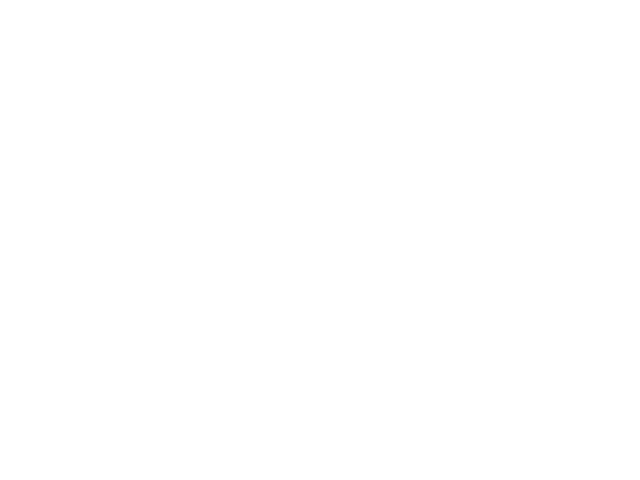

In [2]:
%matplotlib widget
xs = [14, 24, 43, 47, 54, 66, 74, 89, 12, 
      44, 1, 2, 3, 4, 5, 9, 8, 7, 6, 5] 
  
ys = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 6, 3, 
      5, 2, 4, 1, 8, 7, 0, 5] 
  
zs = [9, 6, 3, 5, 2, 4, 1, 8, 7, 0, 1, 2,  
      3, 4, 5, 6, 7, 8, 9, 0] 
  
# creating figure 
fig = plt.figure() 
ax = Axes3D(fig) 
  
# creating the plot 
plot_geeks = ax.scatter(xs, ys, zs, color='green') 
  
# setting title and labels 
ax.set_title("3D plot") 
ax.set_xlabel('x-axis') 
ax.set_ylabel('y-axis') 
ax.set_zlabel('z-axis') 
  
# displaying the plot 
plt.show() 


In [3]:
with open("X.trc", "rb") as f:
    X = torch.load(f)
with open("Y.trc", "rb") as f:
    Y = torch.load(f)

In [4]:
X = X.numpy()
Y = Y.numpy()

In [5]:
print(X.shape)
print(Y.shape)

(28133, 12)
(28133, 720)


In [6]:
input_data = X
output_data = Y

In [7]:
def normalise(data):
    return (data - np.min(data)) / (np.max(data) - np.min(data))

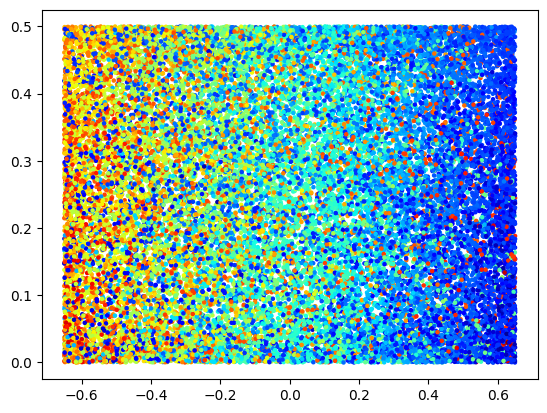

In [9]:
for i in range(0, 1):
    x = []
    y = []
    # z = []
    c = []
    for x_val, y_val in zip(X, Y):
        x.append(x_val[0])
        y.append(x_val[1])
        # z.append(x_val[2])
        c.append(y_val[i])

    fig = plt.figure()
    ax = fig.add_subplot()
    ax.scatter(x, y, c=c, alpha=1, s=5, cmap="jet")
    # plt.savefig(f"test_{i}.png", dpi=1000)
    plt.show()

1860 -0.28426155 0.26657024 -0.9313168


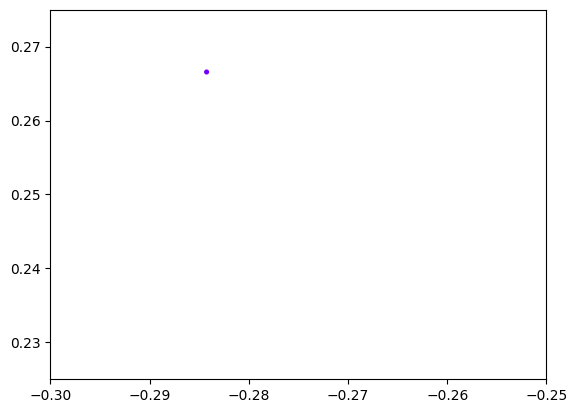

In [15]:
for i, (x_val, y_val) in enumerate(zip(X, Y)):
    if(x_val[-3]< -0.25 and x_val[-3]> -0.3):
        if(x_val[-1]< 0.275 and x_val[-1]> 0.225):
            print(i, x_val[-3], x_val[-1], y_val[0])

x = []
y = []
c = []
for x_val, y_val in zip(X, Y):
    x.append(x_val[-3])
    y.append(x_val[-1])
    c.append(y_val[0])

plt.xlim(-0.3, -0.25)
plt.ylim(0.225, 0.275)

plt.scatter(x, y, c=c, alpha=1, s=7, cmap="hsv")
# plt.savefig(f"test_{i}.png", dpi=1000)
plt.show()

In [16]:
for i in range(792, 792+12):
    x = []
    y = []
    c = []
    for x_val, y_val in zip(X, Y):
        x.append(x_val[-3])
        y.append(x_val[-1])
        c.append(y_val[i])

    plt.scatter(x, y, c=c, alpha=1, s=0.1, cmap="jet")
    plt.show()

IndexError: index 792 is out of bounds for axis 0 with size 720

In [10]:
x = []
y = []
base = X[0]
for i in range(200):
    x_val = i / 200 * 2 - 1
    for j in range(200):
        cur_val = base.copy()
        y_val = j / 200 * 2 - 1
        cur_val[0] += x_val
        cur_val[2] += y_val
        a = sess.run(None, {sess.get_inputs()[0].name: cur_val[None, :]})[0][0]
        x.append(cur_val.tolist())
        y.append(a.tolist())

NameError: name 'sess' is not defined

In [12]:
import json
res = {"x": x, "y": y}
with open("test.json", "w") as f:
    f.write(json.dumps(res))

In [19]:
x_diff = []
y_diff = []
for i in range(len(X)):
    checked_cond = np.linalg.norm(X[i] - X, axis=-1) < 16/45
    checked_cond[i] = False
    mean_X = X[checked_cond].mean(axis=0)
    mean_Y = Y[checked_cond].mean(axis=0)
    x_diff.append(np.linalg.norm(mean_X - X[i]))
    y_diff.append(np.linalg.norm(mean_Y - Y[i]))
    # print(i, len(X[checked_cond]))


/tmp/ipykernel_917811/1503137378.py:6: RuntimeWarning: Mean of empty slice.
  mean_X = X[checked_cond].mean(axis=0)
/tmp/ipykernel_917811/1503137378.py:7: RuntimeWarning: Mean of empty slice.
  mean_Y = Y[checked_cond].mean(axis=0)


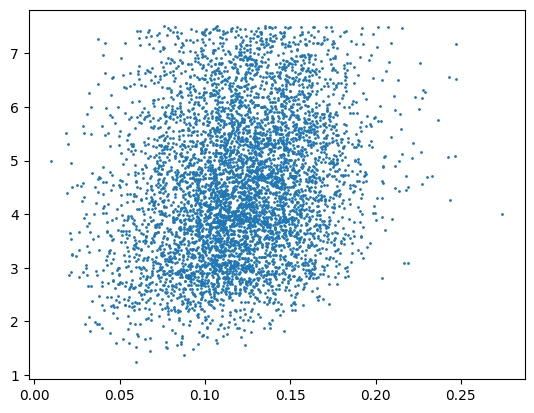

0.8458545345704879


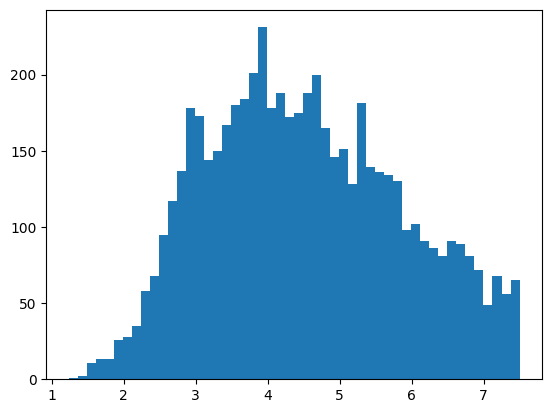

0.8458545345704879


In [21]:
x_diff = np.array(x_diff)
y_diff = np.array(y_diff)

condition = y_diff < 7.5
plt.scatter(x_diff[condition], y_diff[condition], s=1)
plt.show()
print(condition.mean())
plt.hist(y_diff[condition], bins=50)
plt.show()

print(np.mean(condition))

with open("X_filtered.trc", "wb") as f:
    torch.save(torch.tensor(X[condition]), f)
with open("Y_filtered.trc", "wb") as f:
    torch.save(torch.tensor(Y[condition]), f)


In [13]:
for i in range(792, 792+12):
    x = []
    y = []
    c = []
    for x_val, y_val in zip(X[condition], Y[condition]):
        x.append(x_val[-3])
        y.append(x_val[-1])
        c.append(y_val[i])
        
    plt.scatter(x, y, c=c, alpha=1, s=1, cmap="hsv")
    # plt.savefig(f"test_{i}.png", dpi=1000)
    plt.show()

IndexError: index 792 is out of bounds for axis 0 with size 720